In [1]:
!nvidia-smi

Sat Nov 14 09:11:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.57.01              KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4080        On  |   00000000:01:00.0  On |                  N/A |
|  0%   39C    P8             13W /  320W |    1031MiB /  16376MiB |     16%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from numba import cuda, njit, prange
from numba import float64
from numba.cuda.random import create_xoroshiro128p_states
from numba.cuda.random import xoroshiro128p_normal_float32
from numba.cuda.random import xoroshiro128p_uniform_float32

from matplotlib.colors import Normalize
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import time


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/usr/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/usr/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/home/senji77/.local/lib/python3.10/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/senji77/.local/lib/python3.10/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/home/senji77/.local/lib/python3.10/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: numpy.core.multiarray failed to import

In [120]:
L = 64
N = L * L
J = 1.0

q0 = np.pi / 4
D = np.sqrt(2) * np.tan(q0)
J2 = J / (4 * np.cos(q0))

B_z = 0.0

replicas = 64
adapt_every = 500
sample_every = 1000
seed_dmi = 2026
seed_frustration = 2027

n_therm = 1000000
n_measure = 2000000
sigma_initial = 0.6
T = np.linspace(3, 0.2, 100)

In [121]:
def random_spin_field():
    spins = np.random.normal(size=(L, L, 3))
    spins /= np.linalg.norm(spins, axis=2, keepdims=True)
    return spins

lattice = random_spin_field()
print(lattice.shape)

(64, 64, 3)


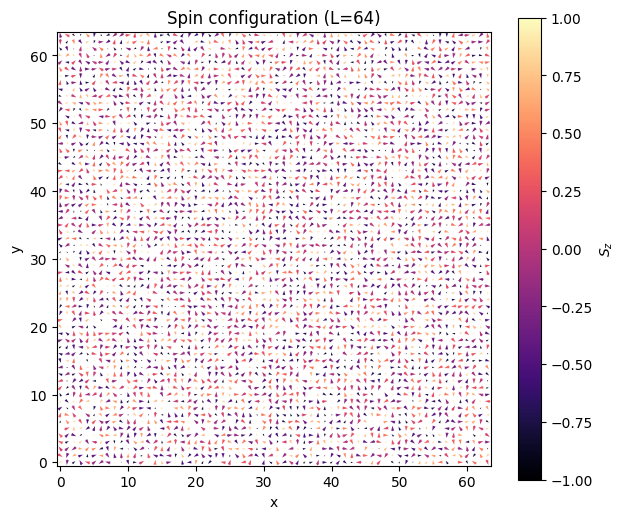

In [122]:
L = lattice.shape[0]

Sx = lattice[:, :, 0].T
Sy = lattice[:, :, 1].T
Sz = lattice[:, :, 2].T

X, Y = np.meshgrid(np.arange(L), np.arange(L))
fig, ax = plt.subplots(figsize=(7, 6))
norm = Normalize(vmin=-1, vmax=1)
cmap = plt.get_cmap("magma")

q = ax.quiver(X, Y, Sx, Sy, Sz, cmap=cmap, norm=norm, pivot="middle", scale_units="xy", scale=1.2)

fig.colorbar(q, ax=ax, label=r"$S_z$")

ax.set_xlim(-0.5, L - 0.5)
ax.set_ylim(-0.5, L - 0.5)
ax.set_aspect("equal")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Spin configuration (L={L})")

plt.show()

$$
H_{\mathrm{DMI}}=-J\sum_{\langle i,j\rangle}\vec{S}_i\cdot\vec{S}_j
-\sum_{\langle i,j\rangle}\vec{D}_{ij}\cdot(\vec{S}_i\times\vec{S}_j)
-B_z\sum_i S_i^z
$$

In [123]:
def delta_energy_dmi(lattice, x, y, trial_spin, B_z):
    L = lattice.shape[0]
    nn = lattice[(x + 1) % L, y] + lattice[(x - 1) % L, y] + lattice[x, (y + 1) % L] + lattice[x, (y - 1) % L]
    old_spin = lattice[x, y]
    E_exchange = -J * np.dot(trial_spin - old_spin, nn)
    E_dmi = -D * (np.dot(trial_spin - old_spin, np.cross(lattice[(x + 1) % L, y] - lattice[(x - 1) % L, y], [1, 0, 0])) + np.dot(trial_spin - old_spin, np.cross(lattice[x, (y + 1) % L] - lattice[x, (y - 1) % L], [0, 1, 0])))
    E_field = -B_z * (trial_spin[2] - old_spin[2])
    return E_exchange + E_dmi + E_field

$$
\mathcal{H}_{\mathrm{Frustration}}
= -J_1\sum_{\langle i,j\rangle}\mathbf{S}_i\cdot\mathbf{S}_j
+J_2\sum_i\mathbf{S}_i\cdot\mathbf{S}_{i+2\hat{x}}
-B_z\sum_i S_i^z
$$

In [124]:
def delta_energy_frustration(lattice, x, y, trial_spin, B_z):
    L = lattice.shape[0]
    nn = lattice[(x + 1) % L, y] + lattice[(x - 1) % L, y] + lattice[x, (y + 1) % L] + lattice[x, (y - 1) % L]
    nnn = lattice[(x + 2) % L, y] + lattice[(x - 2) % L, y]
    old_spin = lattice[x, y]
    E_exchange = -J * np.dot(trial_spin - old_spin, nn)
    E_frustration = J2 * np.dot(trial_spin - old_spin, nnn)
    E_field = -B_z * (trial_spin[2] - old_spin[2])
    return E_exchange + E_frustration + E_field

In [125]:
def magnetization(lattice):
    return np.sum(lattice, axis=(0, 1))


In [126]:
def total_energy_dmi(lattice, B_z):
    nx, ny = lattice.shape[:2]
    E = 0.0

    for x in range(nx):
        for y in range(ny):
            E += -J * np.dot(lattice[x, y], lattice[(x + 1) % nx, y] + lattice[x, (y + 1) % ny])
            E += D * (np.dot(lattice[x, y], np.cross([1, 0, 0], lattice[(x + 1) % nx, y])) + np.dot(lattice[x, y], np.cross([0, 1, 0], lattice[x, (y + 1) % ny])))
            E -= B_z * lattice[x, y, 2]

    return E



def total_energy_frustration(lattice, B_z):
    nx, ny = lattice.shape[:2]
    E = 0.0

    for x in range(nx):
        for y in range(ny):
            nn = lattice[(x + 1) % nx, y] + lattice[x, (y + 1) % ny]
            nnn = lattice[(x + 2) % nx, y]
            E += -J * np.dot(lattice[x, y], nn)
            E += J2 * np.dot(lattice[x, y], nnn)
            E -= B_z * lattice[x, y, 2]

    return E


In [127]:
@cuda.jit
def gpu_sweeps(spins, counts, rng_states, temp, sigma, B_z, model_id, J, J2, D, sweeps):

    replica = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    n_per_color = (nx // 4) * (ny // 2)
    rid = replica * n_per_color + tid

    accepted = 0

    for sweep in range(sweeps):
        for color in range(8):

            cx = color // 2
            cy = color % 2

            x = 4 * (tid // (ny // 2)) + cx
            y = 2 * (tid % (ny // 2)) + cy

            xp = (x + 1) % nx
            xm = (x - 1) % nx
            yp = (y + 1) % ny
            ym = (y - 1) % ny

            old_x = spins[replica, x, y, 0]
            old_y = spins[replica, x, y, 1]
            old_z = spins[replica, x, y, 2]

            # Gaussian trial
            tx = old_x + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            ty = old_y + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            tz = old_z + sigma * xoroshiro128p_normal_float32(rng_states, rid)

            norm = math.sqrt(tx*tx + ty*ty + tz*tz)

            if norm > 0.0:
                tx /= norm
                ty /= norm
                tz /= norm

                dx = tx - old_x
                dy = ty - old_y
                dz = tz - old_z

                # Nearest-neighbor exchange
                n0 = (spins[replica, xp, y, 0] + spins[replica, xm, y, 0] + spins[replica, x, yp, 0] + spins[replica, x, ym, 0])
                n1 = (spins[replica, xp, y, 1] + spins[replica, xm, y, 1] + spins[replica, x, yp, 1] + spins[replica, x, ym, 1])
                n2 = (spins[replica, xp, y, 2] + spins[replica, xm, y, 2] + spins[replica, x, yp, 2] + spins[replica, x, ym, 2])

                dE = -J * (dx*n0 + dy*n1 + dz*n2) - B_z*dz

                if model_id == 1:
                    xpp = (x + 2) % nx
                    xmm = (x - 2) % nx

                    dE += J2 * (dx * (spins[replica, xpp, y, 0] + spins[replica, xmm, y, 0]) + dy * (spins[replica, xpp, y, 1] + spins[replica, xmm, y, 1]) + dz * (spins[replica, xpp, y, 2] + spins[replica, xmm, y, 2]))

                else:
                    ax1 = spins[replica, xp, y, 2] - spins[replica, xm, y, 2]
                    ax2 = -(spins[replica, xp, y, 1] - spins[replica, xm, y, 1])

                    ay0 = -(spins[replica, x, yp, 2] - spins[replica, x, ym, 2])
                    ay2 = spins[replica, x, yp, 0] - spins[replica, x, ym, 0]

                    dE -= D * (dx*ay0 + dy*ax1 + dz*(ax2 + ay2))

                if dE <= 0.0 or (temp > 0.0 and xoroshiro128p_uniform_float32(rng_states, rid) < math.exp(-dE/temp)):
                    spins[replica, x, y, 0] = tx
                    spins[replica, x, y, 1] = ty
                    spins[replica, x, y, 2] = tz
                    accepted += 1
            cuda.syncthreads()
    counts[replica, tid] = accepted

def update_sigma(sigma, R):
    sigma = sigma * math.exp(0.5 * (R - 0.5))
    return min(max(sigma, 1e-3), 2.0)

# def update_sigma(sigma, R):
#     if R >= 1.0:
#         return 60.0

#     sigma = sigma * (0.5 / (1.0 - R))
#     sigma = min(sigma, 60.0)
#     sigma = max(sigma, 1e-8)
#     return sigma


In [128]:
@njit(parallel=True)
def measure_batch_fast(spins, B_z, model_id, J, J2, D):
    replicas, nx, ny, _ = spins.shape
    energies = np.empty(replicas, dtype=np.float64)
    magnetizations = np.empty((replicas, 3), dtype=np.float64)

    for r in prange(replicas):
        energy = 0.0
        mx = 0.0
        my = 0.0
        mz = 0.0

        for x in range(nx):
            xp = (x + 1) % nx
            xpp = (x + 2) % nx

            for y in range(ny):
                yp = (y + 1) % ny

                sx = np.float64(spins[r, x, y, 0])
                sy = np.float64(spins[r, x, y, 1])
                sz = np.float64(spins[r, x, y, 2])

                ex = np.float64(spins[r, xp, y, 0])
                ey = np.float64(spins[r, xp, y, 1])
                ez = np.float64(spins[r, xp, y, 2])

                fx = np.float64(spins[r, x, yp, 0])
                fy = np.float64(spins[r, x, yp, 1])
                fz = np.float64(spins[r, x, yp, 2])

                energy -= J * (sx * (ex + fx) + sy * (ey + fy) + sz * (ez + fz)) + B_z * sz

                if model_id == 1:
                    energy += J2 * (sx * spins[r, xpp, y, 0] + sy * spins[r, xpp, y, 1] + sz * spins[r, xpp, y, 2])
                else:
                    energy -= D * (sy * ez - sz * ey + sz * fx - sx * fz)

                mx += sx
                my += sy
                mz += sz

        energies[r] = energy
        magnetizations[r, 0] = mx
        magnetizations[r, 1] = my
        magnetizations[r, 2] = mz

    return energies, magnetizations

In [129]:
print("Kernel OK")

Kernel OK


In [ ]:
@cuda.jit
def measure_gpu(spins, energies, magnetizations, B_z, model_id, J, J2, D):
    r = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    sh_e = cuda.shared.array(256, dtype=float64)
    sh_mx = cuda.shared.array(256, dtype=float64)
    sh_my = cuda.shared.array(256, dtype=float64)
    sh_mz = cuda.shared.array(256, dtype=float64)

    e = 0.0
    mx = 0.0
    my = 0.0
    mz = 0.0

    for k in range(tid, nx * ny, cuda.blockDim.x):
        x = k // ny
        y = k % ny
        xp = (x + 1) % nx
        yp = (y + 1) % ny

        sx = float64(spins[r, x, y, 0])
        sy = float64(spins[r, x, y, 1])
        sz = float64(spins[r, x, y, 2])

        ax = float64(spins[r, xp, y, 0])
        ay = float64(spins[r, xp, y, 1])
        az = float64(spins[r, xp, y, 2])

        bx = float64(spins[r, x, yp, 0])
        by = float64(spins[r, x, yp, 1])
        bz = float64(spins[r, x, yp, 2])

        e -= J * (sx * (ax + bx) + sy * (ay + by) + sz * (az + bz))
        e -= B_z * sz

        if model_id == 1:
            xpp = (x + 2) % nx

            e += J2 * (
                sx * float64(spins[r, xpp, y, 0])
                + sy * float64(spins[r, xpp, y, 1])
                + sz * float64(spins[r, xpp, y, 2])
            )

        else:
            e -= D * (
                sy * az - sz * ay
                + sz * bx - sx * bz
            )

        mx += sx
        my += sy
        mz += sz

    sh_e[tid] = e
    sh_mx[tid] = mx
    sh_my[tid] = my
    sh_mz[tid] = mz

    cuda.syncthreads()

    stride = cuda.blockDim.x // 2

    while stride > 0:
        if tid < stride:
            sh_e[tid] += sh_e[tid + stride]
            sh_mx[tid] += sh_mx[tid + stride]
            sh_my[tid] += sh_my[tid + stride]
            sh_mz[tid] += sh_mz[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        energies[r] = sh_e[0]
        magnetizations[r, 0] = sh_mx[0]
        magnetizations[r, 1] = sh_my[0]
        magnetizations[r, 2] = sh_mz[0]


In [ ]:

def simulate_temp(lattice, T, B_z, model, replicas, adapt_every, sample_every, seed, n_therm_run, n_measure_run, sigma_initial):
    model_id = 0 if model == "dmi" else 1

    nx, ny = lattice.shape[:2]
    N = nx * ny
    n_per_color = (nx // 4) * (ny // 2)

    batch = np.repeat(lattice[None], replicas, axis=0).astype(np.float32)

    counts_host = np.empty((replicas, n_per_color), dtype=np.int32)
    E_host = np.empty(replicas, dtype=np.float64)
    M_host = np.empty((replicas, 3), dtype=np.float64)

    d_spins = cuda.to_device(batch)
    d_counts = cuda.device_array((replicas, n_per_color), dtype=np.int32)
    d_energies = cuda.device_array(replicas, dtype=np.float64)
    d_magnetizations = cuda.device_array((replicas, 3), dtype=np.float64)

    rng_states = create_xoroshiro128p_states(replicas * n_per_color, seed=seed)

    gpu_sweeps[replicas, n_per_color](
        d_spins, d_counts, rng_states,
        1.0, sigma_initial, B_z, model_id, J, J2, D, 1
    )

    measure_gpu[replicas, 256](
        d_spins, d_energies, d_magnetizations,
        B_z, model_id, J, J2, D
    )

    cuda.synchronize()
    d_spins.copy_to_device(batch)

    c_vs_t = []
    kai_vs_t = []
    m_vs_t = []
    e_vs_t = []
    r_vs_t = []
    sigma_vs_t = []

    n_batches = (n_measure_run + sample_every - 1) // sample_every

    for t in T:
        start_time = time.perf_counter()
        sigma = sigma_initial

        # Thermalization
        for start in range(0, n_therm_run, adapt_every):
            steps = min(adapt_every, n_therm_run - start)

            gpu_sweeps[replicas, n_per_color](
                d_spins, d_counts, rng_states,
                t, sigma, B_z, model_id, J, J2, D, steps
            )

            d_counts.copy_to_host(counts_host)
            R = counts_host.sum(dtype=np.int64) / (replicas * N * steps)
            sigma = update_sigma(sigma, R)

        # Measurement
        energies = np.empty(n_batches * replicas, dtype=np.float64)
        magnetizations = np.empty((n_batches * replicas, 3), dtype=np.float64)

        accepted_sum = 0
        sample_idx = 0

        for start in range(0, n_measure_run, sample_every):
            steps = min(sample_every, n_measure_run - start)

            gpu_sweeps[replicas, n_per_color](
                d_spins, d_counts, rng_states,
                t, sigma, B_z, model_id, J, J2, D, steps
            )

            d_counts.copy_to_host(counts_host)
            accepted_sum += counts_host.sum(dtype=np.int64)

            measure_gpu[replicas, 256](
                d_spins, d_energies, d_magnetizations,
                B_z, model_id, J, J2, D
            )

            d_energies.copy_to_host(E_host)
            d_magnetizations.copy_to_host(M_host)

            energies[sample_idx:sample_idx + replicas] = E_host
            magnetizations[sample_idx:sample_idx + replicas] = M_host
            sample_idx += replicas

        E_mean = np.mean(energies)

        M_abs = np.linalg.norm(magnetizations, axis=1)
        M_abs_mean = np.mean(M_abs)

        c = np.mean((energies - E_mean) ** 2) / (N * t ** 2)
        Kai = np.mean((M_abs - M_abs_mean) ** 2) / (N * t)

        R_mean = accepted_sum / (replicas * N * n_measure_run)

        c_vs_t.append(c)
        kai_vs_t.append(Kai)
        m_vs_t.append(M_abs_mean / N)
        e_vs_t.append(E_mean / N)
        r_vs_t.append(R_mean)
        sigma_vs_t.append(sigma)

        elapsed_time = time.perf_counter() - start_time

        print(
            f"{model} | T={t:.4f} | Time={elapsed_time:.2f} s | "
            f"E/N={E_mean/N:.4f} | M/N={M_abs_mean/N:.4f} | "
            f"C={c:.4f} | Chi={Kai:.4f} | "
            f"R={R_mean:.4f} | Sigma={sigma:.4f}",
            flush=True
        )

    return (
        np.array(c_vs_t),
        np.array(kai_vs_t),
        np.array(m_vs_t),
        np.array(e_vs_t),
        np.array(r_vs_t),
        np.array(sigma_vs_t)
    )


In [131]:
c_vs_t_dmi, kai_vs_t_dmi, m_vs_t_dmi, e_vs_t_dmi, r_vs_t_dmi, sigma_vs_t_dmi = simulate_temp(lattice, T, B_z, "dmi", replicas, adapt_every, sample_every, seed_dmi, n_therm, n_measure, sigma_initial)
c_vs_t_frustration, kai_vs_t_frustration, m_vs_t_frustration, e_vs_t_frustration, r_vs_t_frustration, sigma_vs_t_frustration = simulate_temp(lattice, T, B_z, "frustration", replicas, adapt_every, sample_every, seed_frustration, n_therm, n_measure, sigma_initial)

/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


dmi | Starting T=3.0000
dmi | T=3.0000 | Time=341.99 s | E/N=-0.5298 | M/N=0.0176 | C=0.1839 | Chi=0.0753 | R=0.7391 | Sigma=2.0000
dmi | Starting T=2.9717
dmi | T=2.9717 | Time=339.46 s | E/N=-0.5349 | M/N=0.0176 | C=0.1872 | Chi=0.0768 | R=0.7367 | Sigma=2.0000
dmi | Starting T=2.9434
dmi | T=2.9434 | Time=339.38 s | E/N=-0.5404 | M/N=0.0177 | C=0.1918 | Chi=0.0771 | R=0.7343 | Sigma=2.0000
dmi | Starting T=2.9152
dmi | T=2.9152 | Time=340.42 s | E/N=-0.5458 | M/N=0.0177 | C=0.1959 | Chi=0.0784 | R=0.7318 | Sigma=2.0000
dmi | Starting T=2.8869
dmi | T=2.8869 | Time=339.93 s | E/N=-0.5513 | M/N=0.0177 | C=0.1982 | Chi=0.0793 | R=0.7292 | Sigma=2.0000
dmi | Starting T=2.8586
dmi | T=2.8586 | Time=340.12 s | E/N=-0.5570 | M/N=0.0178 | C=0.2016 | Chi=0.0798 | R=0.7267 | Sigma=2.0000
dmi | Starting T=2.8303
dmi | T=2.8303 | Time=340.48 s | E/N=-0.5628 | M/N=0.0178 | C=0.2080 | Chi=0.0818 | R=0.7240 | Sigma=2.0000
dmi | Starting T=2.8020
dmi | T=2.8020 | Time=340.60 s | E/N=-0.5688 | M/N=0

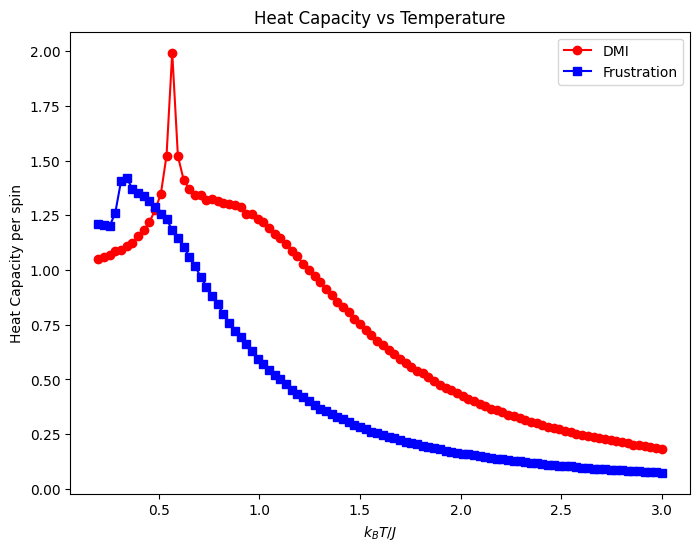

In [132]:
plt.figure(figsize=(8, 6))
plt.plot(T, c_vs_t_dmi, marker="o", color="red", label="DMI") 
plt.plot(T, c_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Heat Capacity per spin")
plt.title("Heat Capacity vs Temperature")
plt.legend()
plt.show()

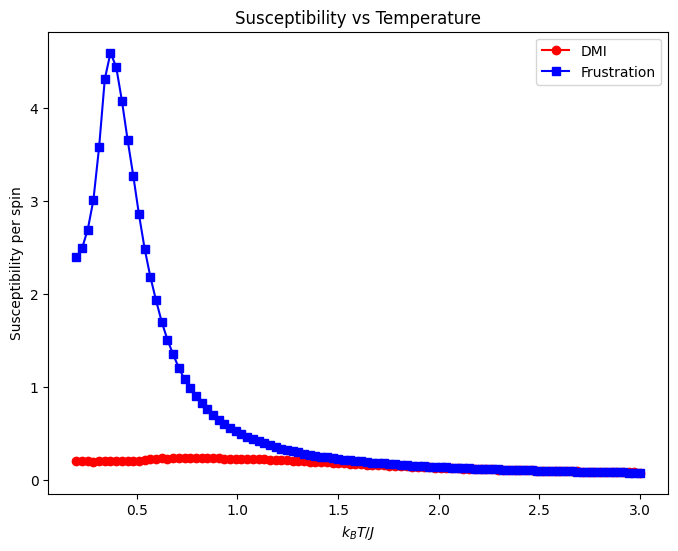

In [133]:
plt.figure(figsize=(8, 6))
plt.plot(T, kai_vs_t_dmi, marker="o", color="red", label="DMI")
plt.plot(T, kai_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Susceptibility per spin")
plt.title("Susceptibility vs Temperature")
plt.legend()
plt.show()

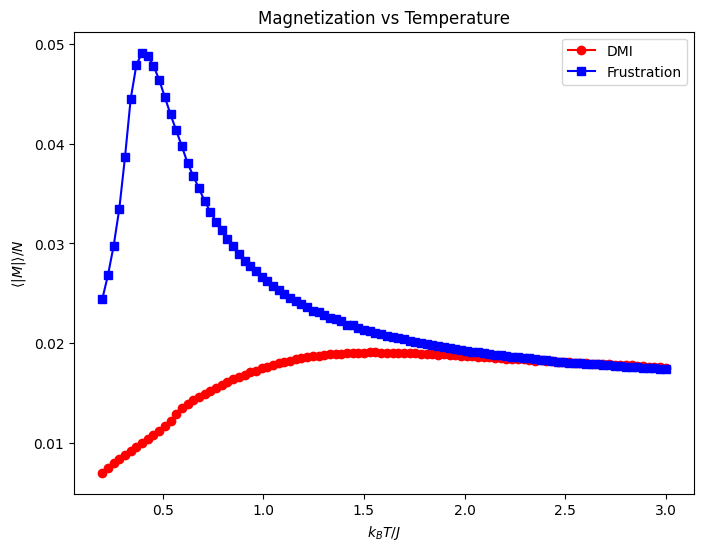

In [134]:
plt.figure(figsize=(8, 6))
plt.plot(T, m_vs_t_dmi, marker="o", color="red", label="DMI")
plt.plot(T, m_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle |M| \rangle/N$")
plt.title("Magnetization vs Temperature")
plt.legend()
plt.show()

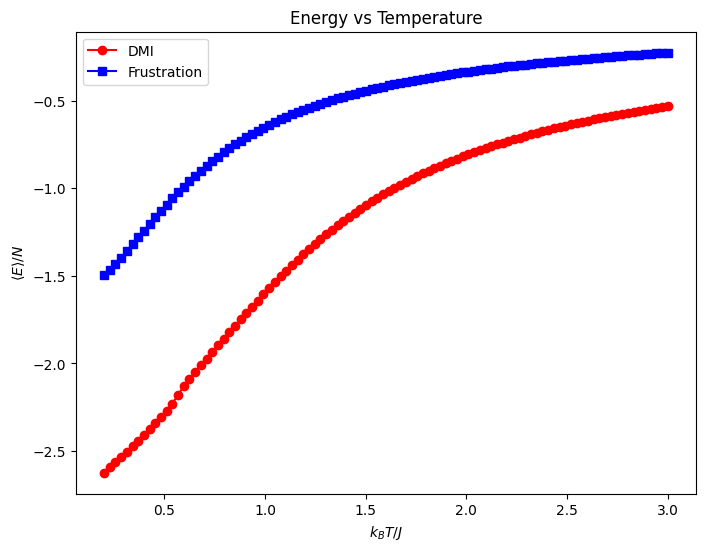

In [135]:
plt.figure(figsize=(8, 6))
plt.plot(T, e_vs_t_dmi, marker="o", color="red", label="DMI")
plt.plot(T, e_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle E \rangle/N$")
plt.title("Energy vs Temperature")
plt.legend()
plt.show()

In [136]:
import pandas as pd

df = pd.DataFrame({
    "T": T,
    "C_DMI": c_vs_t_dmi,
    "Kai_DMI": kai_vs_t_dmi,
    "M_DMI": m_vs_t_dmi,
    "E_DMI": e_vs_t_dmi,
    "R_DMI": r_vs_t_dmi,
    "Sigma_DMI": sigma_vs_t_dmi,
    "C_Frustration": c_vs_t_frustration,
    "Kai_Frustration": kai_vs_t_frustration,
    "M_Frustration": m_vs_t_frustration,
    "E_Frustration": e_vs_t_frustration,
    "R_Frustration": r_vs_t_frustration,
    "Sigma_Frustration": sigma_vs_t_frustration
})

df.to_csv("simulation_results.csv", index=False)